# Lab 02 — Modeling và đánh giá

ResNet18 / DenseNet121

[EDA](01_lab02_eda.ipynb) · [Walkthrough](../walkthrough_lab_02.md) · [Cấu hình đã chạy](../config/cpu_full.json)

In [1]:
from pathlib import Path
import os, sys
root = next(p for p in [Path(os.getenv('LAB02_ROOT', '.')).resolve(), *Path.cwd().resolve().parents] if (p / 'src/notebook_views.py').exists())
sys.path.insert(0, str(root))
from src import notebook_views as view
ROOT, RUN, OUT = view.context()
print("Saved evidence:", RUN.name)

Saved evidence: 20261024T075133Z_cifar10_cpu_full64_71863a0e


### Huấn luyện tùy chọn trên GPU

Mặc định chỉ xem artifact đã lưu. Đổi `TRAIN=True` để chạy baseline mới bằng [experiment.py](../src/experiment.py), cần GPU, dataset và weights; chưa chạy nhánh này trong đợt sửa notebook. Tuning T0–T4 ở cuối vẫn là kế hoạch riêng.

In [2]:
TRAIN = False
if TRAIN:
    from src.experiment import run_suite
    RUN = run_suite(ROOT / 'config/full.json', work_dir=ROOT, device_override='cuda')
    ROOT, RUN, OUT = view.context()
print('Mode:', 'train' if TRAIN else 'saved artifacts')

Mode: saved artifacts


## 1. Chiến lược thích nghi

Head-only → fine-tune block cuối. Bảng tóm tắt thay cho in toàn bộ kiến trúc; code ở [models.py](../src/models.py).

In [3]:
view.architecture_summary(RUN)

,model,stage,total,trainable,unfrozen_blocks
0,resnet18,head,11181642,5130,classifier
1,resnet18,finetune,11181642,8398858,layer4 + fc
2,densenet121,head,6964106,10250,classifier
3,densenet121,finetune,6964106,2170378,denseblock4 + norm5 + classifier


## 2. Learning rate và batch size

Chỉ chọn bằng validation. Run hiện tại dùng AdamW; chưa so sánh optimizer.

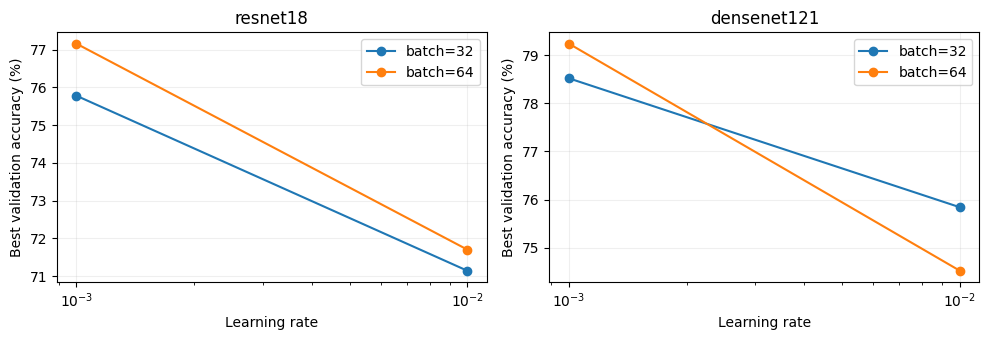

In [4]:
view.lr_search(RUN, OUT)

## 3. Hội tụ

Đường nét đứt: head; nét liền: fine-tune. Trục epoch bắt đầu lại ở từng giai đoạn. Chỉ có 2 epoch fine-tune.

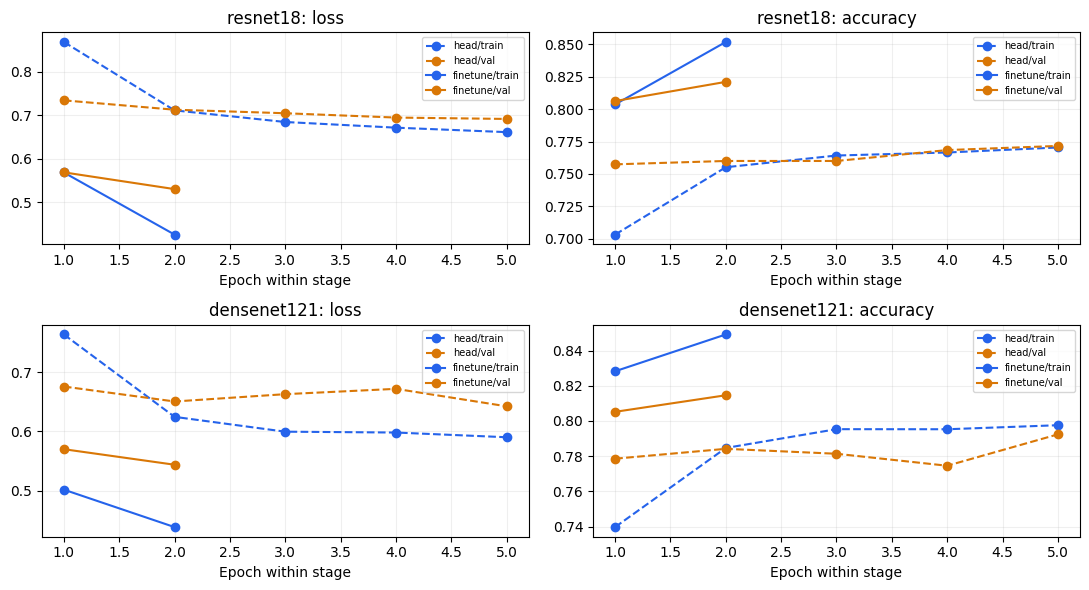

In [5]:
view.learning_curves(RUN, OUT)

## 4. Accuracy, loss và thời gian

Fine-tune: 81,49% / 81,53%, chênh **0,04 điểm phần trăm**. DenseNet dùng cache prefix, ResNet chạy ảnh đầy đủ: chi phí ghi nhận không phải benchmark công bằng giữa kiến trúc. Pipeline gồm trích xuất + toàn bộ head search + fine-tune; không gồm EDA, báo cáo và test.

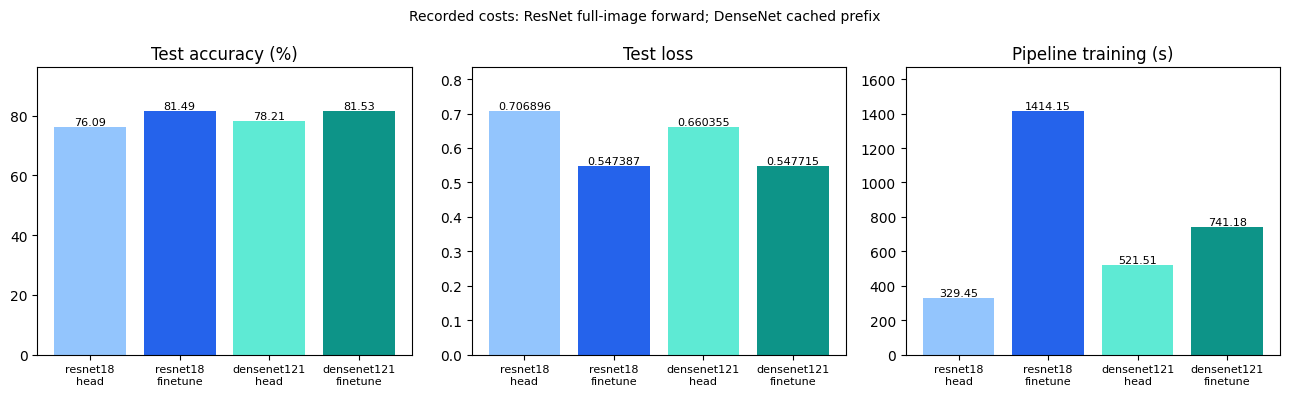

,model,stage,accuracy,loss,macro_f1,best_val_accuracy,train_seconds,pipeline_training_seconds,test_seconds,execution
0,resnet18,head,0.7609,0.7069,0.7611,0.7716,8.8886,329.4474,64.0027,pooled_feature_cache
1,resnet18,finetune,0.8149,0.5474,0.8146,0.8210,1084.6990,1414.1464,62.7633,full_image_forward
2,densenet121,head,0.7821,0.6604,0.7811,0.7924,8.9819,521.5133,100.4044,pooled_feature_cache
3,densenet121,finetune,0.8153,0.5477,0.8151,0.8146,219.6618,741.1751,92.3854,cached_frozen_prefix


In [6]:
view.quality_cost(RUN, OUT)

## 5. Sai ở đâu?

TPR = recall; FPR được tính one-vs-rest từ confusion counts. Bảng đầy đủ theo lớp được lưu và hiển thị.

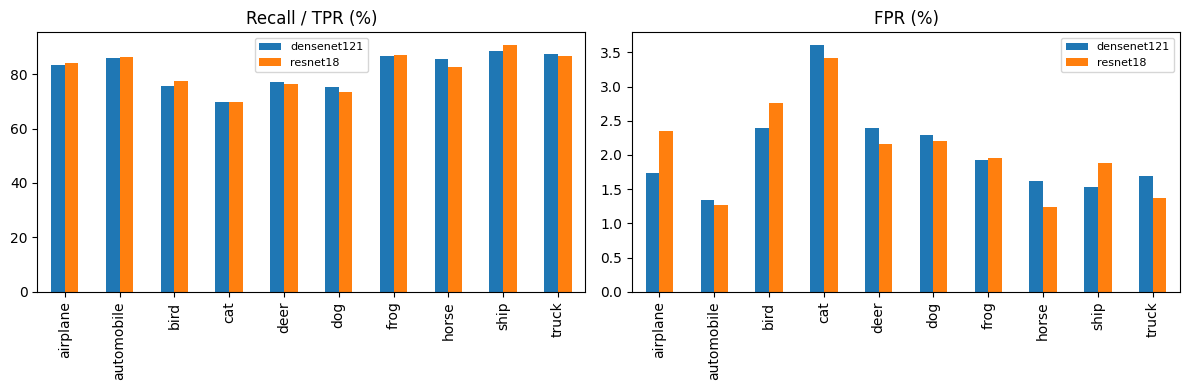

,model,stage,class,precision,recall_tpr,f1,fpr
10,resnet18,finetune,airplane,0.7992,0.840,0.8191,0.0234
11,resnet18,finetune,automobile,0.8833,0.863,0.8730,0.0127
12,resnet18,finetune,bird,0.7578,0.776,0.7668,0.0276
13,resnet18,finetune,cat,0.6948,0.699,0.6969,0.0341
14,resnet18,finetune,deer,0.7977,0.765,0.7810,0.0216
15,resnet18,finetune,dog,0.7878,0.735,0.7605,0.0220
16,resnet18,finetune,frog,0.8319,0.871,0.8510,0.0196
17,resnet18,finetune,horse,0.8815,0.826,0.8529,0.0123
18,resnet18,finetune,ship,0.8431,0.908,0.8743,0.0188
19,resnet18,finetune,truck,0.8756,0.866,0.8708,0.0137


In [7]:
view.errors(RUN, OUT)

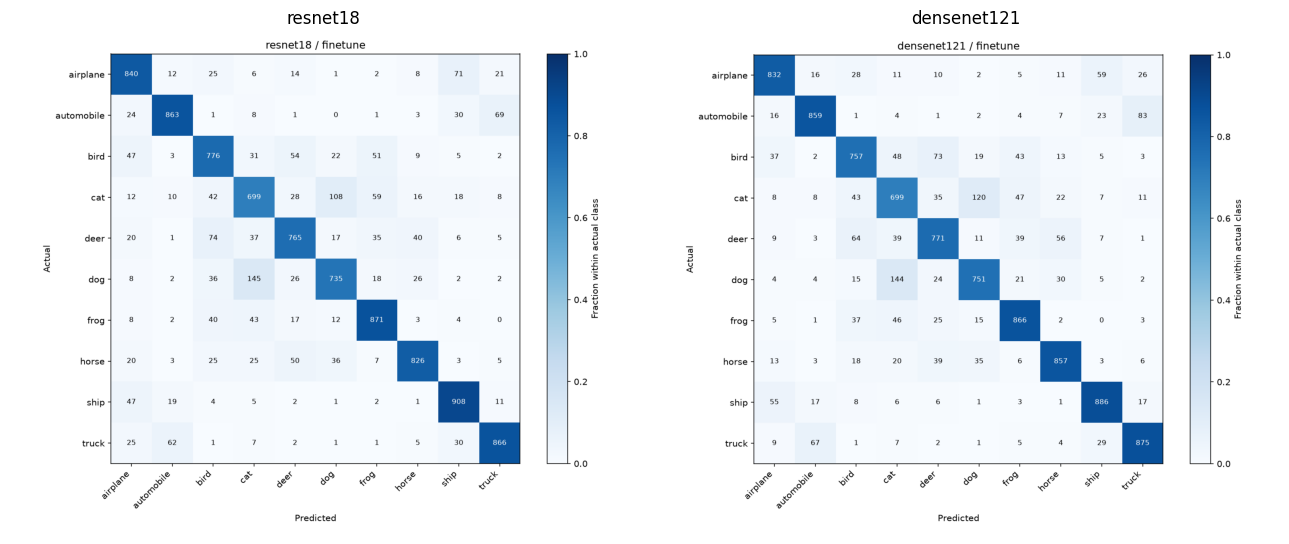

In [8]:
view.evidence(RUN, 'confusion_matrix')

Lỗi dog → cat: ResNet 145/1000 ảnh dog; DenseNet 144/1000. Lưới sau chỉ minh họa tối đa 8 đúng và 8 sai, không thể dùng để ước lượng accuracy.

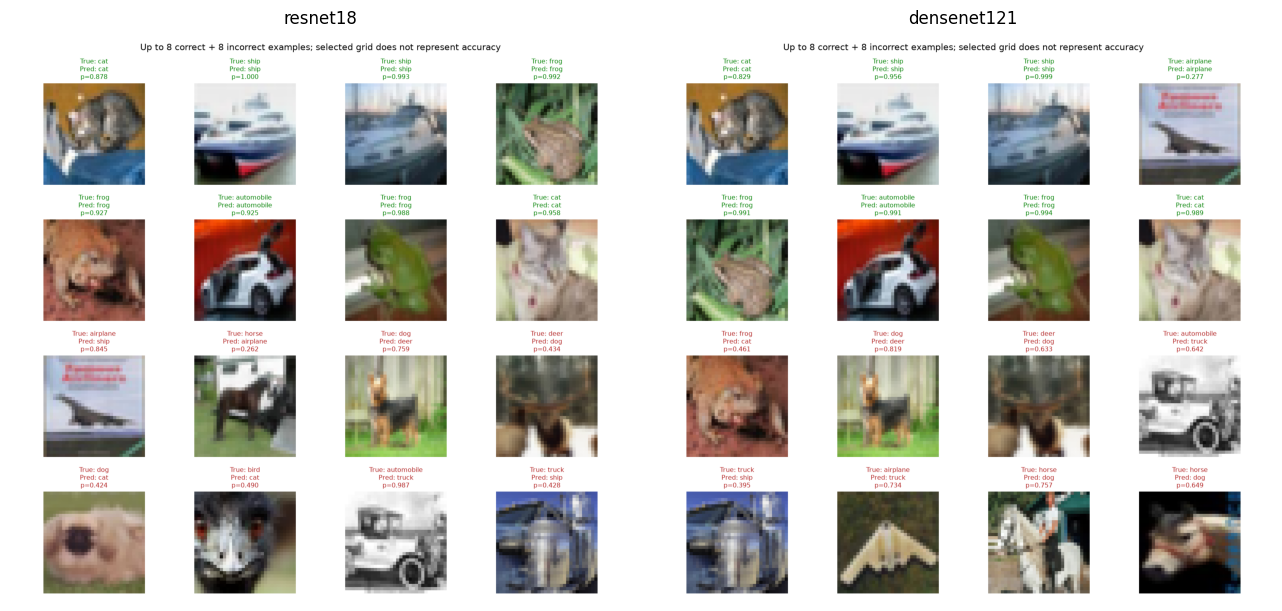

In [9]:
view.evidence(RUN, 'prediction_examples')

## 6. Save/load và theo dõi

Bảng dưới là kiểm chứng đã ghi nhận, không thực hiện lại inference. Dùng [infer.py](../scripts/infer.py) với checkpoint để kiểm tra mới. TensorBoard: `tensorboard --logdir outputs/runs`.

In [10]:
view.roundtrip(RUN)

,model,stage,samples,max_probability_error,passed
0,resnet18,head,8,0.0,True
1,resnet18,finetune,8,0.0,True
2,densenet121,head,8,0.0,True
3,densenet121,finetune,8,0.0,True


## 7. Thí nghiệm tiếp theo — chưa chạy

Thay từng yếu tố: LR → optimizer → độ sâu unfreeze. Giữ split/seed, ngân sách và chế độ thực thi giống nhau; chọn bằng validation, test chỉ sau khi khóa kế hoạch. Mở thêm block có thể cải thiện hoặc gây overfit, chưa có kết quả để khẳng định.

In [11]:
view.tuning_plan(ROOT)

,id,change,optimizer,backbone_lr,head_lr,unfreeze,status
0,T0,Matched baseline,AdamW,1e-5,1e-4,last block,proposed
1,T1,LR search only,AdamW,"3e-6, 1e-5, 3e-5",10 x backbone,last block,proposed
2,T2,Optimizer comparison,AdamW vs SGD(momentum=0.9),"AdamW: T1 winner; SGD: 1e-4, 3e-4, 1e-3",10 x backbone,last block,proposed
3,T3,Unfreeze depth only,T2 winner,T2 winner,T2 winner,ResNet layer3+layer4; DenseNet denseblock3+tra...,proposed
4,T4,Scheduler ablation,T2 winner,T2 winner,T2 winner,T3 selected depth,proposed: constant vs cosine over 10 epochs


Thực thi baseline: `python scripts/run.py --config config/full.json` trên GPU. Kế hoạch mở rộng tại [tuning_plan.json](../config/tuning_plan.json) là đặc tả thí nghiệm, chưa phải cấu hình CLI. Xem [walkthrough](../walkthrough_lab_02.md#15-loss-function-and-optimization-design) để biết LR, optimizer và block cần mở.